## Task 1: Import libraries and load the dataset

In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, make_scorer,
    confusion_matrix, classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
)

CSV_PATH = "Marketingcampaigns.csv"

# In Google Colab, upload the CSV if it is not already in the working folder
if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        CSV_PATH = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(f"Put {CSV_PATH} in the same folder as this notebook.")

df = pd.read_csv(CSV_PATH)
print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (20, 9)


## Task 2: Display the first five records

In [6]:
df.head()

,Customer id,Age,Gender,Location,Email Opened,Email Clicked,Product page visit,Discount offered,Purchased
0,1,22,0,Perth,1,1,3,1,1
1,2,55,0,Auckland,1,0,0,0,0
2,3,15,1,Sydney,0,1,2,1,1
3,4,25,0,Brisbane,1,1,5,1,0
4,5,36,1,Brisbane,0,1,1,1,0


## Task 3: Inspect the dataset

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Customer id         20 non-null     int64 
 1   Age                 20 non-null     int64 
 2   Gender              20 non-null     int64 
 3   Location            20 non-null     object
 4   Email Opened        20 non-null     int64 
 5   Email Clicked       20 non-null     int64 
 6   Product page visit  20 non-null     int64 
 7   Discount offered    20 non-null     int64 
 8   Purchased           20 non-null     int64 
dtypes: int64(8), object(1)
memory usage: 1.5+ KB


In [8]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer id,20.0,NaN,NaN,NaN,10.5,5.91608,1.0,5.75,10.5,15.25,20.0
Age,20.0,NaN,NaN,NaN,38.25,15.382406,15.0,24.5,38.0,53.5,62.0
Gender,20.0,NaN,NaN,NaN,0.55,0.510418,0.0,0.0,1.0,1.0,1.0
Location,20,4,Perth,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Email Opened,20.0,NaN,NaN,NaN,0.5,0.512989,0.0,0.0,0.5,1.0,1.0
Email Clicked,20.0,NaN,NaN,NaN,0.6,0.502625,0.0,0.0,1.0,1.0,1.0
Product page visit,20.0,NaN,NaN,NaN,2.1,1.68273,0.0,1.0,2.0,3.0,5.0
Discount offered,20.0,NaN,NaN,NaN,0.5,0.512989,0.0,0.0,0.5,1.0,1.0
Purchased,20.0,NaN,NaN,NaN,0.5,0.512989,0.0,0.0,0.5,1.0,1.0


## Task 4: Check missing values, duplicates, data types and class balance

In [9]:
print("Missing values per column:")
print(df.isnull().sum().sort_values(ascending=False))
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer ids:", df["Customer id"].duplicated().sum())
print("\nData types:")
print(df.dtypes)

print("\nTarget balance (Purchased):")
balance = df["Purchased"].value_counts().to_frame("customers")
balance["share"] = (balance["customers"] / len(df)).round(2)
print(balance)

print("\nPurchase rate by location:")
print(df.groupby("Location")["Purchased"].agg(customers="count", purchase_rate="mean").round(2))

Missing values per column:
Customer id           0
Age                   0
Gender                0
Location              0
Email Opened          0
Email Clicked         0
Product page visit    0
Discount offered      0
Purchased             0
dtype: int64

Duplicate rows: 0
Duplicate customer ids: 0

Data types:
Customer id            int64
Age                    int64
Gender                 int64
Location              object
Email Opened           int64
Email Clicked          int64
Product page visit     int64
Discount offered       int64
Purchased              int64
dtype: object

Target balance (Purchased):
           customers  share
Purchased                  
1                 10    0.5
0                 10    0.5

Purchase rate by location:
          customers  purchase_rate
Location                          
Auckland          3           0.33
Brisbane          3           0.00
Perth             8           0.75
Sydney            6           0.50


## Task 5: Preprocess the data
We remove exact duplicate rows and the identifier `Customer id` (it carries no predictive meaning). This dataset has no missing values, but the pipeline in Task 9 still imputes them (median for numbers, most frequent for categories) so the model also works on incomplete new records.

In [10]:
df = df.drop_duplicates().copy()
df.columns = df.columns.str.strip()
df = df.drop(columns=["Customer id"])
df["Location"] = df["Location"].str.strip()

df["Purchased"] = pd.to_numeric(df["Purchased"], errors="coerce")
df = df.dropna(subset=["Purchased"]).copy()
df["Purchased"] = df["Purchased"].astype(int)

print("Shape after basic cleaning:", df.shape)
print("Remaining missing values:", int(df.isnull().sum().sum()))

Shape after basic cleaning: (20, 8)
Remaining missing values: 0


## Task 6: Select independent variables (X) and target (y)

In [11]:
target = "Purchased"
X = df.drop(columns=[target])
y = df[target]
print("Target:", target)
print("Number of features:", X.shape[1])
print("Feature columns:")
print(X.columns.tolist())

Target: Purchased
Number of features: 7
Feature columns:
['Age', 'Gender', 'Location', 'Email Opened', 'Email Clicked', 'Product page visit', 'Discount offered']


## Task 7: Identify numeric and categorical columns
`Gender`, `Email Opened`, `Email Clicked` and `Discount offered` are already coded 0/1, so they are used as numeric inputs. Only `Location` is text and gets one-hot encoded.

In [12]:
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()
print("Numeric features:", numeric_features)
print("\nCategorical features:", categorical_features)

Numeric features: ['Age', 'Gender', 'Email Opened', 'Email Clicked', 'Product page visit', 'Discount offered']

Categorical features: ['Location']


## Task 8: Split into 80% training and 20% testing data
`stratify=y` keeps the purchased / not-purchased ratio the same in both parts, which matters with so few rows.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training features:", X_train.shape)
print("Testing features :", X_test.shape)
print("Training targets :", y_train.shape)
print("Testing targets  :", y_test.shape)
print("\nPurchased in training set:", y_train.value_counts().to_dict())
print("Purchased in testing set :", y_test.value_counts().to_dict())

Training features: (16, 7)
Testing features : (4, 7)
Training targets : (16,)
Testing targets  : (4,)

Purchased in training set: {0: 8, 1: 8}
Purchased in testing set : {0: 2, 1: 2}


## Task 9: Build preprocessing and train the Logistic Regression model
The preprocessing is fitted only on the training data, which helps prevent data leakage. Numeric features are standardised because logistic regression is regularised and works best when features are on a similar scale.

In [14]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
])
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")
print("Intercept:", round(float(model.named_steps["classifier"].intercept_[0]), 4))

feature_names = (
    model.named_steps["preprocessor"]
    .get_feature_names_out()
)
feature_names = pd.Series(feature_names).str.replace(r"^(numeric|categorical)__", "", regex=True)
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": model.named_steps["classifier"].coef_[0],
})
coef_df["Odds ratio"] = np.exp(coef_df["Coefficient"])
coef_df = coef_df.reindex(coef_df["Coefficient"].abs().sort_values(ascending=False).index).reset_index(drop=True)
coef_df.round(3)

Logistic Regression model trained successfully.
Intercept: -0.1408


,Feature,Coefficient,Odds ratio
0,Location_Brisbane,-1.094,0.335
1,Discount offered,0.811,2.250
2,Location_Perth,0.679,1.972
3,Location_Sydney,0.288,1.334
4,Age,-0.230,0.794
5,Email Clicked,-0.133,0.875
6,Location_Auckland,0.127,1.135
7,Email Opened,0.111,1.117
8,Product page visit,0.086,1.090
9,Gender,0.076,1.079


## Task 10: Predict purchases for the test data

In [15]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]   # probability of class 1 (purchased)

results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred,
    "Purchase probability": y_proba.round(3),
})
results["Correct?"] = np.where(results["Actual"] == results["Predicted"], "Yes", "No")
results

,Actual,Predicted,Purchase probability,Correct?
0,0,0,0.270,Yes
1,0,0,0.317,Yes
2,1,1,0.770,Yes
3,1,0,0.382,No


## Task 11: Evaluate the model (accuracy, precision, recall, F1, ROC-AUC)

In [16]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_proba)
train_acc = accuracy_score(y_train, model.predict(X_train))

print(f"Accuracy (test)  : {acc:.3f}")
print(f"Precision        : {prec:.3f}")
print(f"Recall           : {rec:.3f}")
print(f"F1 score         : {f1:.3f}")
print(f"ROC-AUC          : {auc:.3f}")
print(f"Accuracy (train) : {train_acc:.3f}")
print(f"Baseline accuracy (always predict the majority class): {max(y_test.mean(), 1 - y_test.mean()):.3f}")

print("\nConfusion matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(
    confusion_matrix(y_test, y_pred),
    index=["Actual: not purchased", "Actual: purchased"],
    columns=["Pred: not purchased", "Pred: purchased"],
))

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Not purchased", "Purchased"], zero_division=0))

Accuracy (test)  : 0.750
Precision        : 1.000
Recall           : 0.500
F1 score         : 0.667
ROC-AUC          : 1.000
Accuracy (train) : 0.938
Baseline accuracy (always predict the majority class): 0.500

Confusion matrix (rows = actual, columns = predicted):
                       Pred: not purchased  Pred: purchased
Actual: not purchased                    2                0
Actual: purchased                        1                1

Classification report:
               precision    recall  f1-score   support

Not purchased       0.67      1.00      0.80         2
    Purchased       1.00      0.50      0.67         2

     accuracy                           0.75         4
    macro avg       0.83      0.75      0.73         4
 weighted avg       0.83      0.75      0.73         4



In [17]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
cv_scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
}
cv_results = cross_validate(model, X, y, cv=cv, scoring=cv_scoring)

print("Repeated 5-fold cross-validation on all 20 customers (mean ± std over 50 folds):")
for name in cv_scoring:
    scores = cv_results[f"test_{name}"]
    print(f"  {name:<10}: {scores.mean():.3f} ± {scores.std():.3f}")

Repeated 5-fold cross-validation on all 20 customers (mean ± std over 50 folds):
  accuracy  : 0.535 ± 0.212
  precision : 0.500 ± 0.316
  recall    : 0.560 ± 0.356
  f1        : 0.503 ± 0.289
  roc_auc   : 0.605 ± 0.288


## Task 12: Plot the confusion matrix and ROC curve

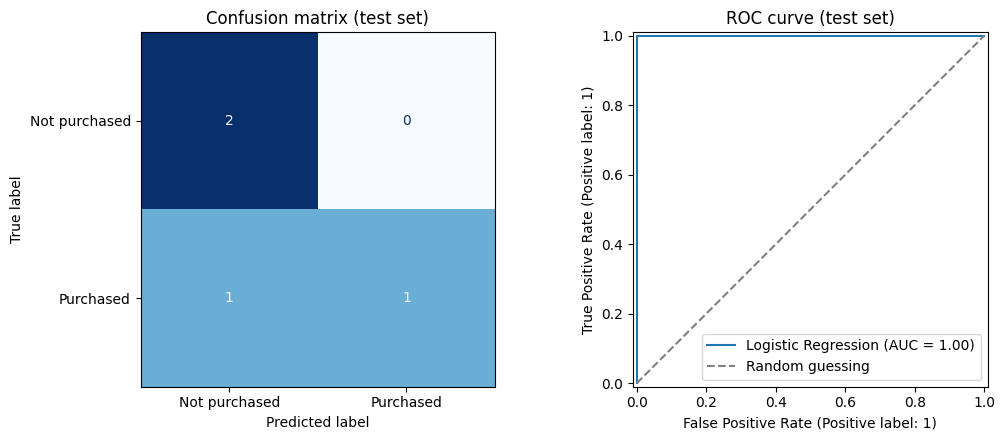

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Not purchased", "Purchased"],
    cmap="Blues", colorbar=False, ax=axes[0],
)
axes[0].set_title("Confusion matrix (test set)")

RocCurveDisplay.from_predictions(y_test, y_proba, name="Logistic Regression", ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guessing")
axes[1].set_title("ROC curve (test set)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

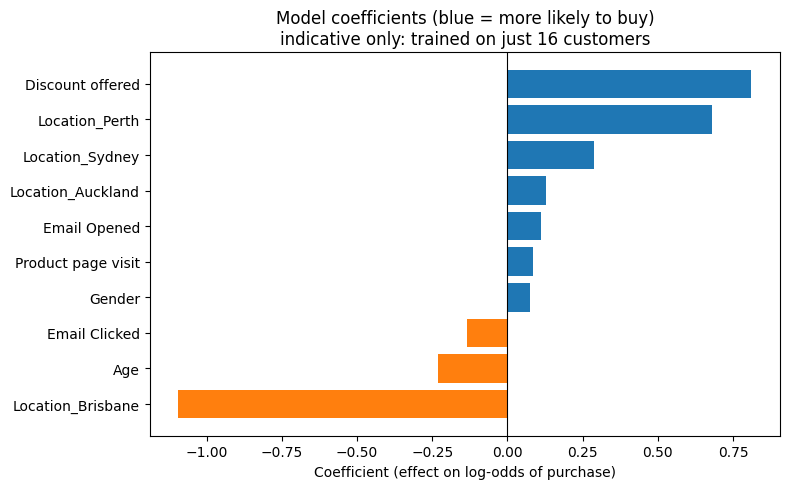

In [19]:
plot_df = coef_df.sort_values("Coefficient")
plt.figure(figsize=(8, 5))
plt.barh(plot_df["Feature"], plot_df["Coefficient"],
         color=np.where(plot_df["Coefficient"] >= 0, "tab:blue", "tab:orange"))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (effect on log-odds of purchase)")
plt.title("Model coefficients (blue = more likely to buy)\nindicative only: trained on just 16 customers")
plt.tight_layout()
plt.show()

## Task 13: Interpret the evaluation metrics

In [20]:
n_test = len(y_test)
cv_acc = cv_results["test_accuracy"].mean()
cv_auc = cv_results["test_roc_auc"].mean()

print(f"Accuracy  = {acc:.2f}: {acc * 100:.0f}% of the {n_test} test customers were classified correctly.")
print(f"Precision = {prec:.2f}: when the model predicts 'Purchased', it is right {prec * 100:.0f}% of the time.")
print(f"Recall    = {rec:.2f}: the model finds {rec * 100:.0f}% of the customers who really purchased.")
print(f"F1 score  = {f1:.2f}: the balance of precision and recall (1.0 is perfect).")
print(f"ROC-AUC   = {auc:.2f}: chance that a random buyer gets a higher purchase probability than a random non-buyer (0.5 = guessing).")

baseline = max(y.mean(), 1 - y.mean())   # accuracy of always guessing the majority class

print(f"\nCross-validated accuracy = {cv_acc:.2f}, ROC-AUC = {cv_auc:.2f} (guessing: accuracy {baseline:.2f}, ROC-AUC 0.50).")
print(f"Training accuracy = {train_acc:.2f}, so the model fits the 16 training customers much better than unseen ones.")

if cv_acc - baseline < 0.10:
    print(f"\nConclusion: cross-validated accuracy is within 10 points of guessing, so on this small dataset the model has NOT learned a dependable pattern. "
          f"The test-set scores above ({acc:.2f} accuracy, {auc:.2f} AUC) are most likely luck from a {n_test}-customer test set.")
else:
    print("\nConclusion: cross-validated accuracy is clearly above guessing, so the model has picked up a real signal, "
          "although 20 customers is still too few to be confident.")
print("More campaign data is needed before using this model for real decisions.")

Accuracy  = 0.75: 75% of the 4 test customers were classified correctly.
Precision = 1.00: when the model predicts 'Purchased', it is right 100% of the time.
Recall    = 0.50: the model finds 50% of the customers who really purchased.
F1 score  = 0.67: the balance of precision and recall (1.0 is perfect).
ROC-AUC   = 1.00: chance that a random buyer gets a higher purchase probability than a random non-buyer (0.5 = guessing).

Cross-validated accuracy = 0.54, ROC-AUC = 0.60 (guessing: accuracy 0.50, ROC-AUC 0.50).
Training accuracy = 0.94, so the model fits the 16 training customers much better than unseen ones.

Conclusion: cross-validated accuracy is within 10 points of guessing, so on this small dataset the model has NOT learned a dependable pattern. The test-set scores above (0.75 accuracy, 1.00 AUC) are most likely luck from a 4-customer test set.
More campaign data is needed before using this model for real decisions.


## Task 14: Predict whether a new customer will purchase
The function accepts a DataFrame with the same feature columns used for training and returns the predicted class and purchase probability.

In [21]:
def predict_purchase(customer_features: pd.DataFrame) -> pd.DataFrame:
    customer_features = customer_features.reindex(columns=X.columns)
    out = customer_features.copy()
    out["Predicted purchase"] = model.predict(customer_features)
    out["Purchase probability"] = model.predict_proba(customer_features)[:, 1].round(3)
    return out

new_customer = pd.DataFrame([{
    "Age": 30,
    "Gender": 1,
    "Location": "Sydney",
    "Email Opened": 1,
    "Email Clicked": 1,
    "Product page visit": 4,
    "Discount offered": 1,
}])

prediction = predict_purchase(new_customer)
print(prediction.T)

row = prediction.iloc[0]
label = "will purchase" if row["Predicted purchase"] == 1 else "will NOT purchase"
print(f"\nThe model predicts this customer {label} (probability {row['Purchase probability']:.1%}).")

                           0
Age                       30
Gender                     1
Location              Sydney
Email Opened               1
Email Clicked              1
Product page visit         4
Discount offered           1
Predicted purchase         1
Purchase probability    0.76

The model predicts this customer will purchase (probability 76.0%).


## Task 15: Gradio interface
Because this dataset has only seven inputs, the form below asks for **all** of them. Gradio is installed in Colab with the next cell.

In [22]:
%pip install gradio

In [23]:
import gradio as gr

location_choices = sorted(X["Location"].unique().tolist())


def gradio_predict(age, gender, location, email_opened, email_clicked, page_visits, discount):
    row = pd.DataFrame([{
        "Age": age,
        "Gender": int(gender),
        "Location": location,
        "Email Opened": int(email_opened),
        "Email Clicked": int(email_clicked),
        "Product page visit": page_visits,
        "Discount offered": int(discount),
    }])[X.columns]
    p = float(model.predict_proba(row)[0, 1])
    return {"Purchased": p, "Not purchased": 1 - p}


demo = gr.Interface(
    fn=gradio_predict,
    inputs=[
        gr.Number(label="Age", value=30, minimum=10, maximum=100, precision=0),
        gr.Radio(["0", "1"], value="0", label="Gender (coded 0 / 1 as in the dataset)"),
        gr.Dropdown(location_choices, value=location_choices[0], label="Location"),
        gr.Checkbox(label="Email opened", value=True),
        gr.Checkbox(label="Email clicked", value=True),
        gr.Slider(0, 10, step=1, value=3, label="Product page visits"),
        gr.Checkbox(label="Discount offered", value=True),
    ],
    outputs=gr.Label(label="Purchase prediction", num_top_classes=2),
    title="Customer Purchase Prediction",
    description="Enter a customer's details to estimate the probability that they purchase after the campaign.",
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://088b1806143214ce2d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Task 16: Save the trained model
This saves the complete preprocessing-plus-classifier pipeline so the Flask app (and anything else) can load it later. Use it with a compatible scikit-learn version.

In [24]:
import joblib

joblib.dump(model, "marketing_purchase_model.joblib")
print("Saved model to marketing_purchase_model.joblib")

# Sanity check: the reloaded model gives identical probabilities
reloaded = joblib.load("marketing_purchase_model.joblib")
print("Reloaded model matches:", np.allclose(reloaded.predict_proba(X_test), model.predict_proba(X_test)))

Saved model to marketing_purchase_model.joblib
Reloaded model matches: True


## Task 17: Flask web app
A small web page with a form plus a JSON API (`/api/predict`). The HTML is embedded in the code, so no `templates` folder is needed.

In [25]:
%pip install -q flask pyngrok

In [26]:
from flask import Flask, request, jsonify, render_template_string
import joblib

flask_model = joblib.load("marketing_purchase_model.joblib")
FEATURES = list(X.columns)
LOCATIONS = sorted(X["Location"].unique().tolist())

PAGE = """
<!doctype html>
<html lang="en">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <title>Customer Purchase Predictor</title>
  <style>
    body { font-family: system-ui, sans-serif; background: #f4f6f8; margin: 0; padding: 24px; color: #1f2933; }
    .card { max-width: 520px; margin: 0 auto; background: #fff; border-radius: 12px; padding: 24px; box-shadow: 0 2px 12px rgba(0,0,0,.08); }
    h1 { font-size: 1.3rem; margin: 0 0 4px; }
    p.sub { margin: 0 0 18px; color: #52606d; font-size: .9rem; }
    label { display: block; font-weight: 600; margin: 12px 0 4px; font-size: .9rem; }
    input, select { width: 100%; padding: 9px; border: 1px solid #cbd2d9; border-radius: 8px; font-size: 1rem; box-sizing: border-box; }
    button { margin-top: 18px; width: 100%; padding: 11px; border: 0; border-radius: 8px; background: #2563eb; color: #fff; font-size: 1rem; cursor: pointer; }
    .result { margin-top: 20px; padding: 14px; border-radius: 8px; }
    .result.buy { background: #e6f6ec; }
    .result.nobuy { background: #fdecec; }
    .error { margin-top: 16px; padding: 12px; border-radius: 8px; background: #fdecec; color: #8a1c1c; }
    .bar { height: 10px; border-radius: 5px; background: #e4e7eb; margin-top: 8px; overflow: hidden; }
    .bar span { display: block; height: 100%; background: #2563eb; }
  </style>
</head>
<body>
  <div class="card">
    <h1>Customer Purchase Predictor</h1>
    <p class="sub">Logistic regression trained on the marketing campaign data.</p>
    <form method="post">
      <label for="age">Age</label>
      <input id="age" name="age" type="number" min="10" max="100" step="1" value="{{ form.age }}" required>

      <label for="gender">Gender (coded 0 / 1 as in the dataset)</label>
      <select id="gender" name="gender">
        <option value="0" {{ 'selected' if form.gender == '0' }}>0</option>
        <option value="1" {{ 'selected' if form.gender == '1' }}>1</option>
      </select>

      <label for="location">Location</label>
      <select id="location" name="location">
        {% for loc in locations %}
        <option value="{{ loc }}" {{ 'selected' if form.location == loc }}>{{ loc }}</option>
        {% endfor %}
      </select>

      <label for="email_opened">Email opened</label>
      <select id="email_opened" name="email_opened">
        <option value="1" {{ 'selected' if form.email_opened == '1' }}>Yes</option>
        <option value="0" {{ 'selected' if form.email_opened == '0' }}>No</option>
      </select>

      <label for="email_clicked">Email clicked</label>
      <select id="email_clicked" name="email_clicked">
        <option value="1" {{ 'selected' if form.email_clicked == '1' }}>Yes</option>
        <option value="0" {{ 'selected' if form.email_clicked == '0' }}>No</option>
      </select>

      <label for="product_page_visit">Product page visits</label>
      <input id="product_page_visit" name="product_page_visit" type="number" min="0" max="50" step="1" value="{{ form.product_page_visit }}" required>

      <label for="discount_offered">Discount offered</label>
      <select id="discount_offered" name="discount_offered">
        <option value="1" {{ 'selected' if form.discount_offered == '1' }}>Yes</option>
        <option value="0" {{ 'selected' if form.discount_offered == '0' }}>No</option>
      </select>

      <button type="submit">Predict</button>
    </form>

    {% if errors %}
    <div class="error">{% for e in errors %}<div>{{ e }}</div>{% endfor %}</div>
    {% endif %}

    {% if result %}
    <div class="result {{ 'buy' if result.prediction == 'Purchased' else 'nobuy' }}">
      <strong>{{ result.prediction }}</strong><br>
      Probability of purchase: {{ '%.1f'|format(result.purchase_probability * 100) }}%
      <div class="bar"><span style="width: {{ result.purchase_probability * 100 }}%"></span></div>
    </div>
    {% endif %}
  </div>
</body>
</html>
"""

DEFAULT_FORM = {
    "age": "30", "gender": "0", "location": LOCATIONS[0],
    "email_opened": "1", "email_clicked": "1",
    "product_page_visit": "3", "discount_offered": "1",
}

# field name -> (label used in the model, minimum, maximum); every one is a whole number
NUMERIC_FIELDS = {
    "age": ("Age", 10, 100),
    "gender": ("Gender", 0, 1),
    "email_opened": ("Email Opened", 0, 1),
    "email_clicked": ("Email Clicked", 0, 1),
    "product_page_visit": ("Product page visit", 0, 50),
    "discount_offered": ("Discount offered", 0, 1),
}


def parse_customer(values):
    """Validate raw form / JSON values. Returns (one-row DataFrame, None) or (None, [error messages])."""
    errors, parsed = [], {}
    for key, (label, low, high) in NUMERIC_FIELDS.items():
        try:
            number = float(values.get(key))
        except (TypeError, ValueError):
            errors.append(f"{label} must be a number.")
            continue
        if not (low <= number <= high) or number != int(number):
            errors.append(f"{label} must be a whole number between {low} and {high}.")
        else:
            parsed[label] = int(number)

    location = str(values.get("location", "")).strip()
    if location not in LOCATIONS:
        errors.append("Location must be one of: " + ", ".join(LOCATIONS) + ".")
    else:
        parsed["Location"] = location

    if errors:
        return None, errors
    return pd.DataFrame([parsed])[FEATURES], None


def predict_row(row):
    probability = float(flask_model.predict_proba(row)[0, 1])
    return {
        "prediction": "Purchased" if probability >= 0.5 else "Not purchased",
        "purchase_probability": round(probability, 4),
    }


app = Flask(__name__)


@app.route("/", methods=["GET", "POST"])
def home():
    form, result, errors = dict(DEFAULT_FORM), None, None
    if request.method == "POST":
        form.update(request.form.to_dict())
        row, errors = parse_customer(request.form)
        if row is not None:
            result = predict_row(row)
    return render_template_string(PAGE, form=form, locations=LOCATIONS, result=result, errors=errors)


@app.route("/api/predict", methods=["POST"])
def api_predict():
    payload = request.get_json(silent=True)
    if not isinstance(payload, dict):
        return jsonify({"errors": ["Send a JSON object."]}), 400
    row, errors = parse_customer(payload)
    if errors:
        return jsonify({"errors": errors}), 400
    return jsonify(predict_row(row))


print("Flask app defined. Routes:", sorted(rule.rule for rule in app.url_map.iter_rules() if rule.endpoint != "static"))

Flask app defined. Routes: ['/', '/api/predict']


**Self-test** the routes before exposing the app (this uses Flask's built-in test client, so no server is needed yet).

In [27]:
client = app.test_client()

page = client.get("/")
print("GET /                ->", page.status_code, "| form shown:", b"Customer Purchase Predictor" in page.data)

form_post = client.post("/", data={
    "age": "30", "gender": "1", "location": "Sydney",
    "email_opened": "1", "email_clicked": "1",
    "product_page_visit": "4", "discount_offered": "1",
})
print("POST / (valid form)  ->", form_post.status_code, "| result shown:", b"Probability of purchase" in form_post.data)

api_ok = client.post("/api/predict", json={
    "age": 30, "gender": 1, "location": "Sydney",
    "email_opened": 1, "email_clicked": 1,
    "product_page_visit": 4, "discount_offered": 1,
})
print("POST /api/predict    ->", api_ok.status_code, api_ok.get_json())

api_bad = client.post("/api/predict", json={"age": 300, "location": "Mars"})
print("POST /api/predict (bad input) ->", api_bad.status_code, api_bad.get_json())

GET /                -> 200 | form shown: True
POST / (valid form)  -> 200 | result shown: True
POST /api/predict    -> 200 {'prediction': 'Purchased', 'purchase_probability': 0.7597}
POST /api/predict (bad input) -> 400 {'errors': ['Age must be a whole number between 10 and 100.', 'Gender must be a number.', 'Email Opened must be a number.', 'Email Clicked must be a number.', 'Product page visit must be a number.', 'Discount offered must be a number.', 'Location must be one of: Auckland, Brisbane, Perth, Sydney.']}


**Start the server** in a background thread so the notebook stays usable.

In [28]:
import threading
import time
import requests
from werkzeug.serving import make_server


class ServerThread(threading.Thread):
    def __init__(self, flask_app, port=5000):
        super().__init__(daemon=True)
        self.server = make_server("127.0.0.1", port, flask_app, threaded=True)

    def run(self):
        self.server.serve_forever()

    def stop(self):
        self.server.shutdown()
        self.server.server_close()

if "server" in globals():
    server.stop()

PORT = 5000
server = ServerThread(app, PORT)
server.start()
time.sleep(1)

print(f"Flask is running at http://127.0.0.1:{PORT}")
print("Health check:", requests.get(f"http://127.0.0.1:{PORT}/").status_code)

INFO:werkzeug:127.0.0.1 - - [14/Oct/2026 05:57:53] "GET / HTTP/1.1" 200 -


Flask is running at http://127.0.0.1:5000
Health check: 200


**Open the app in your browser.** In Google Colab the first cell below opens the app through Colab's own port proxy. The second cell is optional: it creates a public ngrok link if you supply **your own** ngrok auth token (press Enter to skip).

In [29]:
try:
    from google.colab import output
    output.serve_kernel_port_as_window(PORT)
except ImportError:
    print(f"Not running in Colab. Open http://127.0.0.1:{PORT} in your browser.")

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [30]:
import getpass

ngrok_token = os.environ.get("NGROK_AUTH_TOKEN", "")
if not ngrok_token:
    try:
        ngrok_token = getpass.getpass("ngrok auth token (press Enter to skip): ")
    except (EOFError, KeyboardInterrupt):
        ngrok_token = ""

if ngrok_token:
    from pyngrok import ngrok
    ngrok.set_auth_token(ngrok_token)
    public_url = ngrok.connect(PORT)
    print("Public URL:", public_url.public_url)
else:
    print("Skipped ngrok.")

ngrok auth token (press Enter to skip): ··········
Skipped ngrok.
